<a href="https://colab.research.google.com/github/elsiejy/Capstone/blob/main/Capstone_Hotel_Bookings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Overview

As a Data Analyst working for Oasis Hospitality Group, my objective is to analyse historical hotel booking data from 2015 to 2017 to understand booking demand patterns, customer characteristics and factors associated with booking cancellations.

The analysis will focus on identifying seasonal fluctuations in booking demand, understanding the hotel's key customer segments, and examining booking characteristics associated with cancellations. By uncovering these patterns and trends, the project aims to provide actionable insights to support better demand planning, optimise booking management strategies and reduce booking cancellations.

The findings will help make more informed, data-driven decisions about its booking strategies, customer targeting, and demand management.


# Part 1: Descriptive Analysis

### 1. Import libraries
Import the libaries into the notebook

In [5]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# importing sklearn module for predictive analysis
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.preprocessing import MinMaxScaler

# ignore the warnings that may appear
import warnings
warnings.filterwarnings("ignore")

### 2. Import data

Import csv files into the notebook. Here the file is hosted in github thus we will read the file directly from github

In [6]:
# load dataset1: booking.csv
bookings = pd.read_csv('https://raw.githubusercontent.com/elsiejy/Capstone/refs/heads/main/Bookings.csv')
display(bookings.info())
display(bookings.head())
display(bookings.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 28 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Booking_ID                      119390 non-null  int64  
 1   Hotel_ID                        119390 non-null  int64  
 2   Market_Segment_ID               119390 non-null  int64  
 3   Customer_Type_ID                119390 non-null  int64  
 4   Reservation_ID                  119390 non-null  int64  
 5   is_canceled                     119390 non-null  int64  
 6   lead_time                       119390 non-null  int64  
 7   arrival_date_year               119390 non-null  int64  
 8   arrival_date_month              119390 non-null  object 
 9   arrival_date_week_number        119390 non-null  int64  
 10  arrival_date_day_of_month       119390 non-null  int64  
 11  stays_in_weekend_nights         119390 non-null  int64  
 12  stays_in_week_ni

None

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date
0,1,1,1,1,1,0,342,2015,July,27,...,0,0,3,NaN,NaN,0,0.0,0,0,2015-07-01
1,2,1,1,1,1,0,737,2015,July,27,...,0,0,4,NaN,NaN,0,0.0,0,0,2015-07-01
2,3,1,1,1,1,0,7,2015,July,27,...,0,0,0,NaN,NaN,0,75.0,0,0,2015-07-02
3,4,1,2,1,1,0,13,2015,July,27,...,0,0,0,304.0,NaN,0,75.0,0,0,2015-07-02
4,5,1,3,1,1,0,14,2015,July,27,...,0,0,0,240.0,NaN,0,98.0,0,1,2015-07-03


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,...,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,59695.500000,1.664461,4.262032,5.089044,1.380526,0.370416,104.011416,2016.156554,27.165173,15.798241,...,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,34465.068657,0.472181,3.071532,5.250009,0.505913,0.482918,106.863097,0.707476,13.605138,8.780829,...,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,2015.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,29848.250000,1.000000,3.000000,1.000000,1.000000,0.000000,18.000000,2016.000000,16.000000,8.000000,...,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,59695.500000,2.000000,3.000000,3.000000,1.000000,0.000000,69.000000,2016.000000,28.000000,16.000000,...,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,89542.750000,2.000000,4.000000,8.000000,2.000000,1.000000,160.000000,2017.000000,38.000000,23.000000,...,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,119390.000000,2.000000,26.000000,36.000000,3.000000,1.000000,737.000000,2017.000000,53.000000,31.000000,...,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [7]:
# print the number of null values in each column in booking
bookings.isnull().sum()

,0
Booking_ID,0
Hotel_ID,0
Market_Segment_ID,0
Customer_Type_ID,0
Reservation_ID,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0


In [8]:
# load dataset2: customertype.csv
cust_type = pd.read_csv('https://raw.githubusercontent.com/elsiejy/Capstone/refs/heads/main/CustomerTypes.csv')
display(cust_type.info())
display(cust_type.head())
display(cust_type.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Customer_Type_ID  36 non-null     int64 
 1   customer_type     36 non-null     object
 2   deposit_type      36 non-null     object
 3   meal              36 non-null     object
dtypes: int64(1), object(3)
memory usage: 1.3+ KB


None

,Customer_Type_ID,customer_type,deposit_type,meal
0,1,Transient,No Deposit,BB
1,2,Transient,No Deposit,FB
2,3,Transient,No Deposit,HB
3,4,Contract,No Deposit,BB
4,5,Contract,No Deposit,HB


,Customer_Type_ID
count,36.000000
mean,18.500000
std,10.535654
min,1.000000
25%,9.750000
50%,18.500000
75%,27.250000
max,36.000000


In [9]:
# print the number of null values in each column in cust_type
cust_type.isnull().sum()

,0
Customer_Type_ID,0
customer_type,0
deposit_type,0
meal,0


In [10]:
# load dataset3: hotel.csv
hotel_type = pd.read_csv('https://raw.githubusercontent.com/elsiejy/Capstone/refs/heads/main/Hotels.csv')
display(hotel_type.info())
display(hotel_type.head())
display(hotel_type.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Hotel_ID  2 non-null      int64 
 1   hotel     2 non-null      object
dtypes: int64(1), object(1)
memory usage: 164.0+ bytes


None

,Hotel_ID,hotel
0,1,Resort Hotel
1,2,City Hotel


,Hotel_ID
count,2.000000
mean,1.500000
std,0.707107
min,1.000000
25%,1.250000
50%,1.500000
75%,1.750000
max,2.000000


In [11]:
# print the number of null values in each column in hotel_type
hotel_type.isnull().sum()

,0
Hotel_ID,0
hotel,0


In [12]:
# load dataset4: marketsegment.csv
market_seg = pd.read_csv('https://raw.githubusercontent.com/elsiejy/Capstone/refs/heads/main/MarketSegments.csv')
display(market_seg.info())
display(market_seg.head())
display(market_seg.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Market_Segment_ID     26 non-null     int64 
 1   market_segment        26 non-null     object
 2   distribution_channel  26 non-null     object
dtypes: int64(1), object(2)
memory usage: 756.0+ bytes


None

,Market_Segment_ID,market_segment,distribution_channel
0,1,Direct,Direct
1,2,Corporate,Corporate
2,3,Online TA,TA/TO
3,4,Offline TA/TO,TA/TO
4,5,Complementary,Direct


,Market_Segment_ID
count,26.000000
mean,13.500000
std,7.648529
min,1.000000
25%,7.250000
50%,13.500000
75%,19.750000
max,26.000000


In [13]:
# print the number of null values in each column in market_seg
market_seg.isnull().sum()

,0
Market_Segment_ID,0
market_segment,0
distribution_channel,0


In [14]:
# load dataset5: reservationstatus.csv
res_sts = pd.read_csv('https://raw.githubusercontent.com/elsiejy/Capstone/refs/heads/main/ReservationStatus.csv')
display(res_sts .info())
display(res_sts .head())
display(res_sts .describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Reservation_ID      3 non-null      int64 
 1   reservation_status  3 non-null      object
dtypes: int64(1), object(1)
memory usage: 180.0+ bytes


None

,Reservation_ID,reservation_status
0,1,Check-Out
1,2,Canceled
2,3,No-Show


,Reservation_ID
count,3.0
mean,2.0
std,1.0
min,1.0
25%,1.5
50%,2.0
75%,2.5
max,3.0


In [15]:
# print the number of null values in each column in res_sts
res_sts.isnull().sum()

,0
Reservation_ID,0
reservation_status,0


Observation from booking dataset
- There are a total of 119,390 booking records
- Hotel_ID, Market_Segment_ID, Customer_Type_ID, Reservation_ID are foreign keys
- NULL values exist in children, country, agent, company
- reservation_status_date should be date time
- children, agent, and company should be int
- is_repeated_guest and is_canceled should be boolean

Observation from other dataset
- No empty values

### 3. Data Cleansing & Preparation

Let's clean the dataset. We'll identify missing values, handle empty rows, correct data types, and prepare the dataset for analysis.

Dataset 1: Booking
1. Derive check-in date
2. Update data type for reservation_status_date
3. Update data type for is_repeated_guest and is_canceled
4. Update data type for children, agent and company
5. Handle NULL values for children, country, agent, company

In [16]:
# 1. Derive check-in date
# combine arrival_date_year, arrival_date_month and arrival_date_day_of_month into strings
booking_date_strings = (
    bookings['arrival_date_year'].astype(str) + '-' +
    bookings['arrival_date_month'].astype(str) + '-' +
    bookings['arrival_date_day_of_month'].astype(str)
)

# convert booking_date_strings to datetime then format as YYYY-MM-DD text
bookings['checkin_date'] = pd.to_datetime(booking_date_strings).dt.strftime('%Y-%m-%d')

# convert that string into a proper pandas datetime object
bookings['checkin_date'] = pd.to_datetime(booking_date_strings)

# verify that first 5 rows of checkin_date
print(bookings['checkin_date'].head())




0   2015-07-01
1   2015-07-01
2   2015-07-01
3   2015-07-01
4   2015-07-01
Name: checkin_date, dtype: datetime64[ns]


In [17]:
# 2. Update data type for reservation_status_date
# convert reservation_status_date to datetime format
bookings['reservation_status_date'] = pd.to_datetime(bookings['reservation_status_date'])

# view the first 5 rows of reservation_status_date
print(bookings['reservation_status_date'].head())

0   2015-07-01
1   2015-07-01
2   2015-07-02
3   2015-07-02
4   2015-07-03
Name: reservation_status_date, dtype: datetime64[ns]


In [18]:
# 3. Update data type for is_repeated_guest and is_canceled
# change datatype from int to boolean
bookings[['is_repeated_guest', 'is_canceled']] = bookings[['is_repeated_guest', 'is_canceled']].astype(bool)

# verify count of is_repeated_guest and is_canceled
print(bookings['is_canceled'].value_counts())
print(bookings['is_repeated_guest'].value_counts())

# confirm values are only false, true
print(bookings['is_canceled'].unique())
print(bookings['is_repeated_guest'].unique())


is_canceled
False    75166
True     44224
Name: count, dtype: int64
is_repeated_guest
False    115580
True       3810
Name: count, dtype: int64
[False  True]
[False  True]


In [19]:
# 4. Update data type for children, agent and company
# change datatype from float to int
bookings[['children', 'agent', 'company']] = bookings[['children', 'agent', 'company']].astype('Int64')

In [20]:
# 5. Handle NULL values for children, country, agent, company
# handle NULL value for children by replacing NULL with 0
bookings['children'] = bookings['children'].fillna(0)

# handle NULL value for country by replacing NULL with UNKNOWN
bookings['country'] = bookings['country'].fillna('Unknown')

# handle NULL value for agent by replacing NULL with 0
bookings['agent'] = bookings['agent'].fillna(0)

# handle NULL value for company by replacing NULL with 0
bookings['company'] = bookings['company'].fillna(0)

In [21]:
# verify null values for each column in booking
bookings.isnull().sum()

,0
Booking_ID,0
Hotel_ID,0
Market_Segment_ID,0
Customer_Type_ID,0
Reservation_ID,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0


In [22]:
# check booking data
display(bookings.info())
display(bookings.head())
display(bookings.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 29 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   Booking_ID                      119390 non-null  int64         
 1   Hotel_ID                        119390 non-null  int64         
 2   Market_Segment_ID               119390 non-null  int64         
 3   Customer_Type_ID                119390 non-null  int64         
 4   Reservation_ID                  119390 non-null  int64         
 5   is_canceled                     119390 non-null  bool          
 6   lead_time                       119390 non-null  int64         
 7   arrival_date_year               119390 non-null  int64         
 8   arrival_date_month              119390 non-null  object        
 9   arrival_date_week_number        119390 non-null  int64         
 10  arrival_date_day_of_month       119390 non-null  int64  

None

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,checkin_date
0,1,1,1,1,1,False,342,2015,July,27,...,0,3,0,0,0,0.0,0,0,2015-07-01,2015-07-01
1,2,1,1,1,1,False,737,2015,July,27,...,0,4,0,0,0,0.0,0,0,2015-07-01,2015-07-01
2,3,1,1,1,1,False,7,2015,July,27,...,0,0,0,0,0,75.0,0,0,2015-07-02,2015-07-01
3,4,1,2,1,1,False,13,2015,July,27,...,0,0,304,0,0,75.0,0,0,2015-07-02,2015-07-01
4,5,1,3,1,1,False,14,2015,July,27,...,0,0,240,0,0,98.0,0,1,2015-07-03,2015-07-01


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,checkin_date
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390,119390.000000,119390.000000,119390,119390.000000,...,119390.000000,119390.000000,119390.0,119390.0,119390.000000,119390.000000,119390.000000,119390.000000,119390,119390
unique,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,12,NaN,...,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,August,NaN,...,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,75166,NaN,NaN,13877,NaN,...,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
mean,59695.500000,1.664461,4.262032,5.089044,1.380526,NaN,104.011416,2016.156554,NaN,27.165173,...,0.137097,0.221124,74.828319,10.775157,2.321149,101.831122,0.062518,0.571363,2016-07-30 00:24:47.883407104,2016-08-28 16:39:45.727447808
min,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.000000,2015.000000,NaN,1.000000,...,0.000000,0.000000,0.0,0.0,0.000000,-6.380000,0.000000,0.000000,2014-10-17 00:00:00,2015-07-01 00:00:00
25%,29848.250000,1.000000,3.000000,1.000000,1.000000,NaN,18.000000,2016.000000,NaN,16.000000,...,0.000000,0.000000,7.0,0.0,0.000000,69.290000,0.000000,0.000000,2016-02-01 00:00:00,2016-03-13 00:00:00
50%,59695.500000,2.000000,3.000000,3.000000,1.000000,NaN,69.000000,2016.000000,NaN,28.000000,...,0.000000,0.000000,9.0,0.0,0.000000,94.575000,0.000000,0.000000,2016-08-07 00:00:00,2016-09-06 00:00:00
75%,89542.750000,2.000000,4.000000,8.000000,2.000000,NaN,160.000000,2017.000000,NaN,38.000000,...,0.000000,0.000000,152.0,0.0,0.000000,126.000000,0.000000,1.000000,2017-02-08 00:00:00,2017-03-18 00:00:00
max,119390.000000,2.000000,26.000000,36.000000,3.000000,NaN,737.000000,2017.000000,NaN,53.000000,...,72.000000,21.000000,535.0,543.0,391.000000,5400.000000,8.000000,5.000000,2017-09-14 00:00:00,2017-08-31 00:00:00


#### Create df for cleansed data

In [23]:
# create a new df
df = pd.merge(bookings, hotel_type, on='Hotel_ID', how='left')

# merge the rest into new dataset
df = pd.merge(df, market_seg, on='Market_Segment_ID', how='left')
df = pd.merge(df, cust_type, on='Customer_Type_ID', how='left')
df = pd.merge(df, res_sts, on='Reservation_ID', how='left')


In [24]:
# check df data
display(df.info())
display(df.head())
display(df.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   Booking_ID                      119390 non-null  int64         
 1   Hotel_ID                        119390 non-null  int64         
 2   Market_Segment_ID               119390 non-null  int64         
 3   Customer_Type_ID                119390 non-null  int64         
 4   Reservation_ID                  119390 non-null  int64         
 5   is_canceled                     119390 non-null  bool          
 6   lead_time                       119390 non-null  int64         
 7   arrival_date_year               119390 non-null  int64         
 8   arrival_date_month              119390 non-null  object        
 9   arrival_date_week_number        119390 non-null  int64         
 10  arrival_date_day_of_month       119390 non-null  int64  

None

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,total_of_special_requests,reservation_status_date,checkin_date,hotel,market_segment,distribution_channel,customer_type,deposit_type,meal,reservation_status
0,1,1,1,1,1,False,342,2015,July,27,...,0,2015-07-01,2015-07-01,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
1,2,1,1,1,1,False,737,2015,July,27,...,0,2015-07-01,2015-07-01,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
2,3,1,1,1,1,False,7,2015,July,27,...,0,2015-07-02,2015-07-01,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
3,4,1,2,1,1,False,13,2015,July,27,...,0,2015-07-02,2015-07-01,Resort Hotel,Corporate,Corporate,Transient,No Deposit,BB,Check-Out
4,5,1,3,1,1,False,14,2015,July,27,...,1,2015-07-03,2015-07-01,Resort Hotel,Online TA,TA/TO,Transient,No Deposit,BB,Check-Out


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,total_of_special_requests,reservation_status_date,checkin_date,hotel,market_segment,distribution_channel,customer_type,deposit_type,meal,reservation_status
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390,119390.000000,119390.000000,119390,119390.000000,...,119390.000000,119390,119390,119390,119390,119390,119390,119390,119390,119390
unique,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,12,NaN,...,NaN,NaN,NaN,2,8,5,4,3,5,3
top,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,August,NaN,...,NaN,NaN,NaN,City Hotel,Online TA,TA/TO,Transient,No Deposit,BB,Check-Out
freq,NaN,NaN,NaN,NaN,NaN,75166,NaN,NaN,13877,NaN,...,NaN,NaN,NaN,79330,56477,97870,89613,104641,92310,75166
mean,59695.500000,1.664461,4.262032,5.089044,1.380526,NaN,104.011416,2016.156554,NaN,27.165173,...,0.571363,2016-07-30 00:24:47.883407104,2016-08-28 16:39:45.727447808,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.000000,2015.000000,NaN,1.000000,...,0.000000,2014-10-17 00:00:00,2015-07-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,29848.250000,1.000000,3.000000,1.000000,1.000000,NaN,18.000000,2016.000000,NaN,16.000000,...,0.000000,2016-02-01 00:00:00,2016-03-13 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,59695.500000,2.000000,3.000000,3.000000,1.000000,NaN,69.000000,2016.000000,NaN,28.000000,...,0.000000,2016-08-07 00:00:00,2016-09-06 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,89542.750000,2.000000,4.000000,8.000000,2.000000,NaN,160.000000,2017.000000,NaN,38.000000,...,1.000000,2017-02-08 00:00:00,2017-03-18 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,119390.000000,2.000000,26.000000,36.000000,3.000000,NaN,737.000000,2017.000000,NaN,53.000000,...,5.000000,2017-09-14 00:00:00,2017-08-31 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
# remove redundant columns
df = df.drop(columns=['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month','Hotel_ID', 'Market_Segment_ID', 'Customer_Type_ID', 'Reservation_ID'
])

#### Export data to new CSV file

In [26]:
# export df into CSV file
# df.to_csv('bookings_clean.csv', index=False)

# from google.colab import files
# files.download('bookings_clean.csv')


### 4. Visualization

Analyse seasonal booking patterns and demand fluctuations

To examine historical hotel booking trends over time and identify seasonality in booking volumes e.g., peak season and off peak period

Observation: some reservation_status_date are later than check-in date

In [28]:
# Check the date range and data quality
print("Total records:", len(df))
print("Earliest check-in:", df["checkin_date"].min())
print("Latest check-in:", df["checkin_date"].max())
print("Missing check-in dates:", df["checkin_date"].isna().sum())


Total records: 119390
Earliest check-in: 2015-07-01 00:00:00
Latest check-in: 2017-08-31 00:00:00
Missing check-in dates: 0


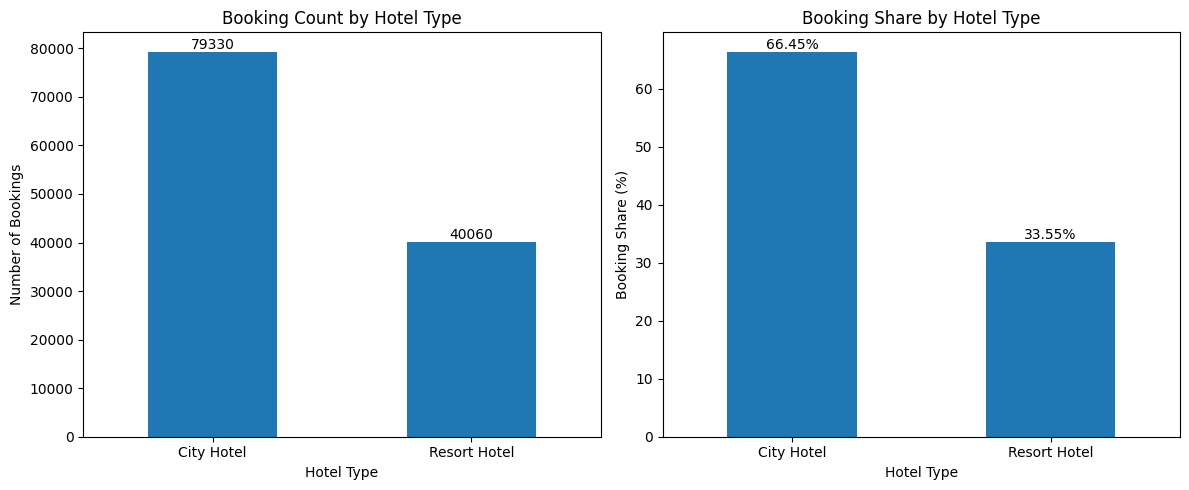

In [36]:
# Calculate booking count and percentage share
hotel_summary = df["hotel"].value_counts().rename_axis("Hotel").to_frame("Booking Count")
hotel_summary["Booking Share (%)"] = (hotel_summary["Booking Count"] / hotel_summary["Booking Count"].sum() * 100)

# Create two side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Booking Count
hotel_summary["Booking Count"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Booking Count by Hotel Type")
axes[0].set_xlabel("Hotel Type")
axes[0].set_ylabel("Number of Bookings")
axes[0].tick_params(axis="x", rotation=0)

# Add data labels
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f")

# Chart 2: Booking Share
hotel_summary["Booking Share (%)"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Booking Share by Hotel Type")
axes[1].set_xlabel("Hotel Type")
axes[1].set_ylabel("Booking Share (%)")
axes[1].tick_params(axis="x", rotation=0)

# Add percentage labels
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()


The dataset contains 119,390 booking records of which 79,330 (66.45%) are associated with City Hotel and 40,060 (33.55%) with Resort Hotel. City Hotel therefore accounts for approximately two-thirds of the recorded bookings.

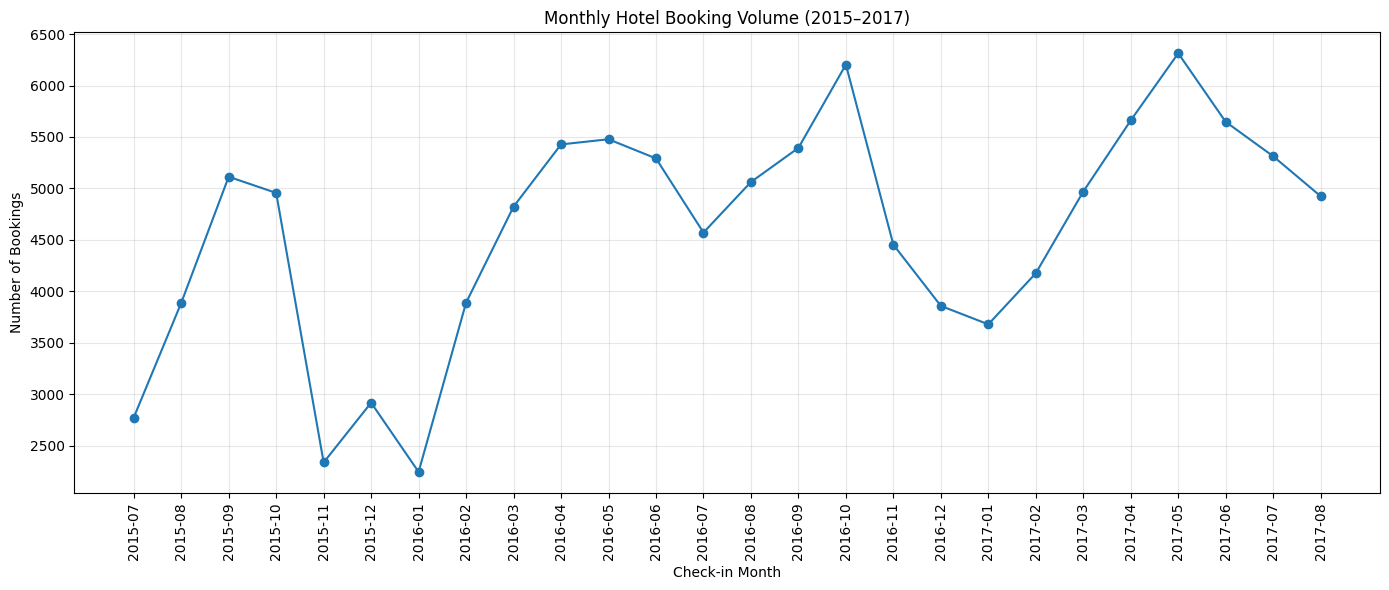

In [37]:
# Group bookings by check-in month
monthly_bookings = (df.groupby(df["checkin_date"].dt.to_period("M")).size().reset_index(name="booking_count"))

monthly_bookings["month"] = (monthly_bookings["checkin_date"].astype(str))

# Plot the monthly trend
plt.figure(figsize=(14, 6))
plt.plot(
    monthly_bookings["month"],
    monthly_bookings["booking_count"],
    marker="o"
)

plt.title("Monthly Hotel Booking Volume (2015–2017)")
plt.xlabel("Check-in Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Findings based on check-in month

- Off-peak period: January 2016 and January 2017 both have relatively low booking volumes.
- Peak period: Booking volume rises towards May in both 2016 and 2017

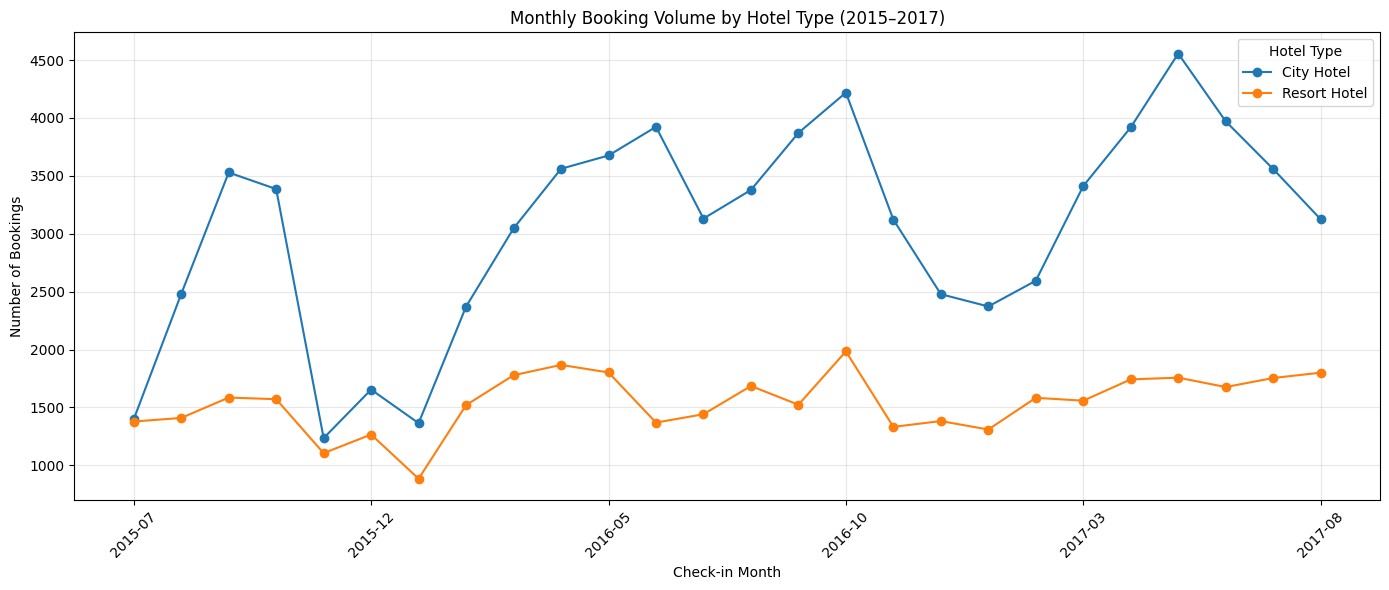

In [32]:
# group bookings by month and hotel type
hotel_monthly = (df.groupby([df["checkin_date"].dt.to_period("M"),"hotel"]).size().reset_index(name="booking_count"))

# Rename the date column and convert to string
hotel_monthly = hotel_monthly.rename(columns={"checkin_date": "month"})

hotel_monthly["month"] = hotel_monthly["month"].astype(str)

# Pivot for plotting
hotel_pivot = hotel_monthly.pivot(
    index="month",
    columns="hotel",
    values="booking_count"
).fillna(0)

# Plot
hotel_pivot.plot(figsize=(14, 6), marker="o")

plt.title("Monthly Booking Volume by Hotel Type (2015–2017)")
plt.xlabel("Check-in Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.legend(title="Hotel Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
